# Indirect losses: sectoral and spatial distribution

Reproduces:

| manuscript | figure file | what |
|---|---|---|
| Main text, `fig:res1` | `fig_sectors_time_space.png` | (A) daily losses of the ten most affected sectors, (B) household losses by district, for 4/8/12-day disruptions |
| Supplementary, `fig:si_sectors` | `fig_sectors_losses_short.png` | top-ten sectors by cumulative loss per duration |

**Data**: representative realizations of the simultaneous multi-basin scenario in
`data/scenarios/230927_simultaneous_{4d,8d,12d}/` (`loss_per_region_sector_time.csv`,
`household_data.json`, `household_table.geojson`); sector names from
`data/reference/sector_table.csv`; GADM level-2 districts and the disrupted road network
from `data/reference/`.

**Environment**: `dsc` conda env (pandas, geopandas, matplotlib, contextily).

All figures in this notebook use one simulation per duration, which is the 'representative realization' also used for the flow maps, which is `loss_per_region_sector_time.csv`, keeping only the Cambodian sectors, so considering domestically supplied goods. There is an additional figure to test weather the represenative simulation can be defined as such.


In [1]:
from pathlib import Path

BUNDLE = Path.cwd()
MC = BUNDLE / "data" / "monte_carlo"
SCEN = BUNDLE / "data" / "scenarios"
REF = BUNDLE / "data" / "reference"
FIGDIR = BUNDLE / "figures" / "generated"
FIGDIR.mkdir(parents=True, exist_ok=True)

import contextily as ctx
ctx.tile.USER_AGENT = "DisruptSC-Cambodia-paper-figures/1.0 (research reproducibility notebooks)"

## Setup and data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx

plt.rcParams['figure.figsize'] = (14, 8)

In [3]:
# Economic data - loss per region, sector, and time
# For 4d and 8d we use the v2 rerun (closer to ensemble median); 12d has no v2.
durations = ['4d', '8d', '12d']

def scen_dir(duration):
    return f'230927_simultaneous_{duration}_v2' if duration in ('4d', '8d') else f'230927_simultaneous_{duration}'

data_dict = {}
for duration in durations:
    df = pd.read_csv(SCEN / f'{scen_dir(duration)}/loss_per_region_sector_time.csv')
    df = df[(df['region'] == 'KHM') & (df['sector'].str.startswith('KHM_'))].copy()
    df = df[df['time_step'] <= 30]
    data_dict[duration] = df

# Sector mapping
sector_mapping = pd.read_csv(REF / 'sector_table.csv')
sector_name_dict = dict(zip('KHM_' + sector_mapping['sector'], sector_mapping['name']))

# Adjust long names
sector_name_dict['KHM_TRL'] = 'Land/Water/Air transport and warehousing'
sector_name_dict['KHM_TRW'] = 'Wholesale trade'
sector_name_dict['KHM_CON'] = 'Construction'
sector_name_dict['KHM_ADM'] = 'Public administration and defense'
sector_name_dict['KHM_ACF'] = 'Accommodation and food service activities'

# Geographic data
admin_boundaries = gpd.read_file(REF / "gadm41_KHM_2.shp")
roads_gdf = gpd.read_file(REF / "roads_with_disruptions.geojson")

# Household data
household_losses = {}
for duration in durations:
    households_tables = pd.read_json(SCEN / f"{scen_dir(duration)}/household_data.json")
    households_points = gpd.read_file(SCEN / f"{scen_dir(duration)}/household_table.geojson")
    
    households_tables["total_loss"] = households_tables["extra_spending"] + households_tables["consumption_loss"]
    # losses on domestically supplied goods: KHM_ entries of the per-sector columns
    per_sector = (pd.DataFrame(households_tables["extra_spending_per_sector"].tolist())
                  .add(pd.DataFrame(households_tables["consumption_loss_per_sector"].tolist()), fill_value=0))
    households_tables["domestic_loss"] = per_sector.filter(regex="^KHM_").sum(axis=1).values
    households_sum = households_tables.groupby("household", as_index=False)[["extra_spending", "consumption_loss", "total_loss", "domestic_loss"]].sum()
    households_points = households_points.merge(households_sum, on="household", how="left")
    households_points = gpd.sjoin(households_points, admin_boundaries[["NAME_2", "geometry"]], how="left", predicate="within")
    
    district_col = "NAME_2" if "NAME_2" in households_points.columns else "NAME_2_right"
    losses_by_district = households_points.groupby(district_col, as_index=False)[["extra_spending", "consumption_loss", "total_loss", "domestic_loss"]].sum()
    if district_col != "NAME_2":
        losses_by_district = losses_by_district.rename(columns={district_col: "NAME_2"})
    
    losses_by_district = admin_boundaries.merge(losses_by_district, on="NAME_2", how="left")
    losses_by_district["total_loss"] = losses_by_district["total_loss"].fillna(0).astype(float)
    losses_by_district["domestic_loss"] = losses_by_district["domestic_loss"].fillna(0).astype(float)
    household_losses[duration] = losses_by_district

Top-ten sectors by cumulative loss (shared across durations) and their colours.

In [4]:
# Identify top 10 sectors by cumulative losses
all_data = pd.concat([df.assign(duration=dur) for dur, df in data_dict.items()])
top_10_sectors = all_data.groupby('sector')['loss'].sum().nlargest(10).index.tolist()

# Assign colors
colors = plt.cm.tab10(np.arange(10))
sector_colors = dict(zip(top_10_sectors, colors))

# Print statistics
print("="*80)
print("SUMMARY STATISTICS")
print("="*80)

for duration in durations:
    df = data_dict[duration]
    total_loss = df['loss'].sum()
    peak_loss = df.groupby('time_step')['loss'].sum().max()
    peak_time = df.groupby('time_step')['loss'].sum().idxmax()
    hh_loss = household_losses[duration]['total_loss'].sum()
    
    print(f"\n{duration} disruption:")
    print(f"  Sectoral losses: {total_loss:.3f} M$")
    print(f"  Household losses: {hh_loss:.3f} M$")
    print(f"  Peak sectoral loss: {peak_loss:.3f} M$")

print(f"\n{'='*80}")
print("Top 10 Sectors:")
print("="*80)
for i, sector in enumerate(top_10_sectors, 1):
    name = sector_name_dict.get(sector, sector)
    total_loss = all_data[all_data['sector'] == sector]['loss'].sum()
    print(f"{i:2d}. {sector.replace('KHM_', '')}: {name} ({total_loss:.3f} M$)")

SUMMARY STATISTICS

4d disruption:
  Sectoral losses: 1.287 M$
  Household losses: 2.242 M$
  Peak sectoral loss: 0.351 M$

8d disruption:
  Sectoral losses: 3.273 M$
  Household losses: 5.213 M$
  Peak sectoral loss: 0.421 M$

12d disruption:
  Sectoral losses: 13.759 M$
  Household losses: 16.726 M$
  Peak sectoral loss: 3.036 M$

Top 10 Sectors:
 1. MBE: Manufacture of beverages (3.817 M$)
 2. TRW: Wholesale trade (2.701 M$)
 3. CRO: Crops (2.259 M$)
 4. ADM: Public administration and defense (1.469 M$)
 5. TRL: Land/Water/Air transport and warehousing (1.401 M$)
 6. FIS: Fishing and aquaculture (1.207 M$)
 7. ACF: Accommodation and food service activities (1.070 M$)
 8. MTO: Manufacture of tobacco products (0.755 M$)
 9. MFO: Manufacture of food products (0.490 M$)
10. CON: Construction (0.459 M$)


### Spatial distribution of households losses per sectors

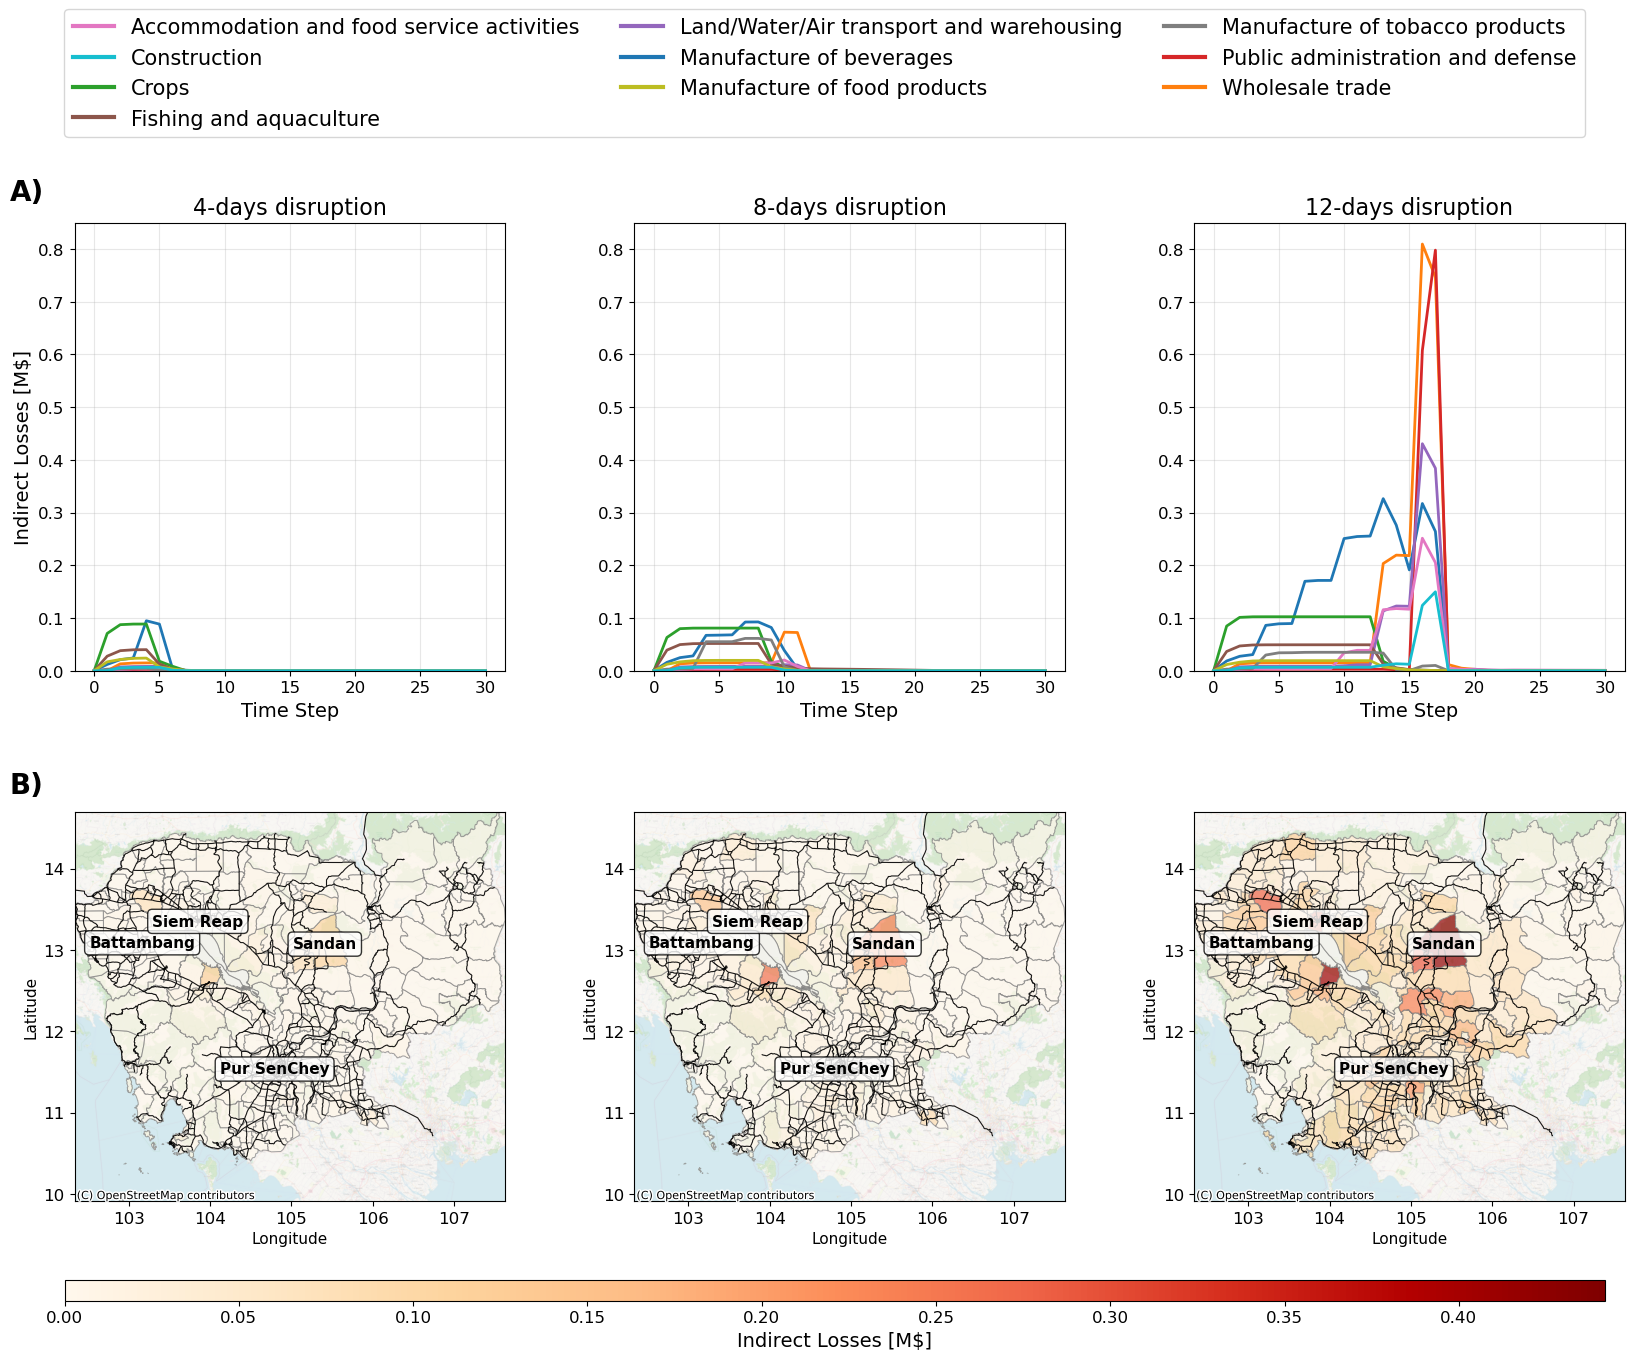

In [5]:
# Combined figure: Sectoral losses time series + Household losses by district
MAP_LOSSES = 'domestic'   # 'domestic' (KHM_ sectors, as panel A) or 'total' (published figure)
map_col = 'domestic_loss' if MAP_LOSSES == 'domestic' else 'total_loss'

fig = plt.figure(figsize=(20, 14))
gs = fig.add_gridspec(2, 3, hspace=0.25, wspace=0.3, top=0.83)

selected_durations = ['4d', '8d', '12d']
vmin = min(household_losses[dur][map_col].min() for dur in selected_durations)
vmax = max(household_losses[dur][map_col].max() for dur in selected_durations)
transport_districts = ["Battambang", "Siem Reap", "Pur SenChey", "Sandan"]

# Row A: Sectoral losses per time step
row1_axes = []
for idx, duration in enumerate(selected_durations):
    df_top = data_dict[duration][data_dict[duration]['sector'].isin(top_10_sectors)]
    ax = fig.add_subplot(gs[0, idx])
    row1_axes.append(ax)
    
    for sector in top_10_sectors:
        sector_data = df_top[df_top['sector'] == sector]
        ax.plot(sector_data['time_step'], sector_data['loss'], 
                linewidth=2, color=sector_colors[sector])
    
    ax.set_xlabel('Time Step', fontsize=14)
    if idx == 0:
        ax.set_ylabel('Indirect Losses [M$]', fontsize=14)
        ax.text(-0.15, 1.05, 'A)', transform=ax.transAxes, fontsize=20, fontweight='bold')
    ax.set_title(f'{duration[:-1]}-days disruption', fontsize=16)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=12)

ylim_max = max(ax.get_ylim()[1] for ax in row1_axes)
for ax in row1_axes:
    ax.set_ylim(0, ylim_max)

# Row B: Household losses by district
for idx, duration in enumerate(selected_durations):
    gdf = household_losses[duration]
    ax = fig.add_subplot(gs[1, idx])
    
    gdf.plot(ax=ax, column=map_col, cmap="OrRd", linewidth=0.7,
             edgecolor="grey", alpha=0.7, legend=False, vmin=vmin, vmax=vmax,
             missing_kwds={"color": "lightgrey"}, zorder=1)
    
    roads_gdf.plot(ax=ax, color='black', linewidth=0.8, alpha=0.9, zorder=2)
    
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom=10, alpha=0.5, zorder=0)
    except:
        pass
    
    gdf_utm = gdf.to_crs('EPSG:32648')
    for district in transport_districts:
        district_data = gdf_utm[gdf_utm['NAME_2'] == district]
        if not district_data.empty:
            centroid_utm = district_data.geometry.centroid.iloc[0]
            centroid = gpd.GeoSeries([centroid_utm], crs='EPSG:32648').to_crs('EPSG:4326').iloc[0]
            ax.annotate(district, xy=(centroid.x, centroid.y), fontsize=11, fontweight='bold',
                       ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', 
                                                           facecolor='white', edgecolor='black', 
                                                           alpha=0.8), zorder=12)
    
    ax.set_xlim(gdf.total_bounds[0], gdf.total_bounds[2])
    ax.set_ylim(gdf.total_bounds[1], gdf.total_bounds[3])
    ax.set_xlabel("Longitude", fontsize=11)
    ax.set_ylabel("Latitude", fontsize=11)
    ax.tick_params(labelsize=12)
    ax.set_aspect('equal')
    
    if idx == 0:
        ax.text(-0.15, 1.05, 'B)', transform=ax.transAxes, fontsize=20, fontweight='bold')

# Legend for sectoral time series
legend_elements = [plt.Line2D([0], [0], color=sector_colors[sector], linewidth=3,
                              label=sector_name_dict.get(sector, sector))
                  for sector in top_10_sectors]
legend_elements = sorted(legend_elements, key=lambda x: x.get_label())
fig.legend(handles=legend_elements, loc='upper center', fontsize=15, ncol=3,
          bbox_to_anchor=(0.5, 0.99), frameon=True)

# Colorbar for household losses
sm = plt.cm.ScalarMappable(cmap='OrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm._A = []
cbar_ax = fig.add_axes([0.12, 0.06, 0.77, 0.015])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', label='Indirect Losses [M$]')
cbar.ax.tick_params(labelsize=12)
cbar.set_label('Indirect Losses [M$]', fontsize=14)

plt.savefig(FIGDIR / 'fig_sectors_time_space.png', dpi=100, bbox_inches='tight')
plt.show()

### Sector losses

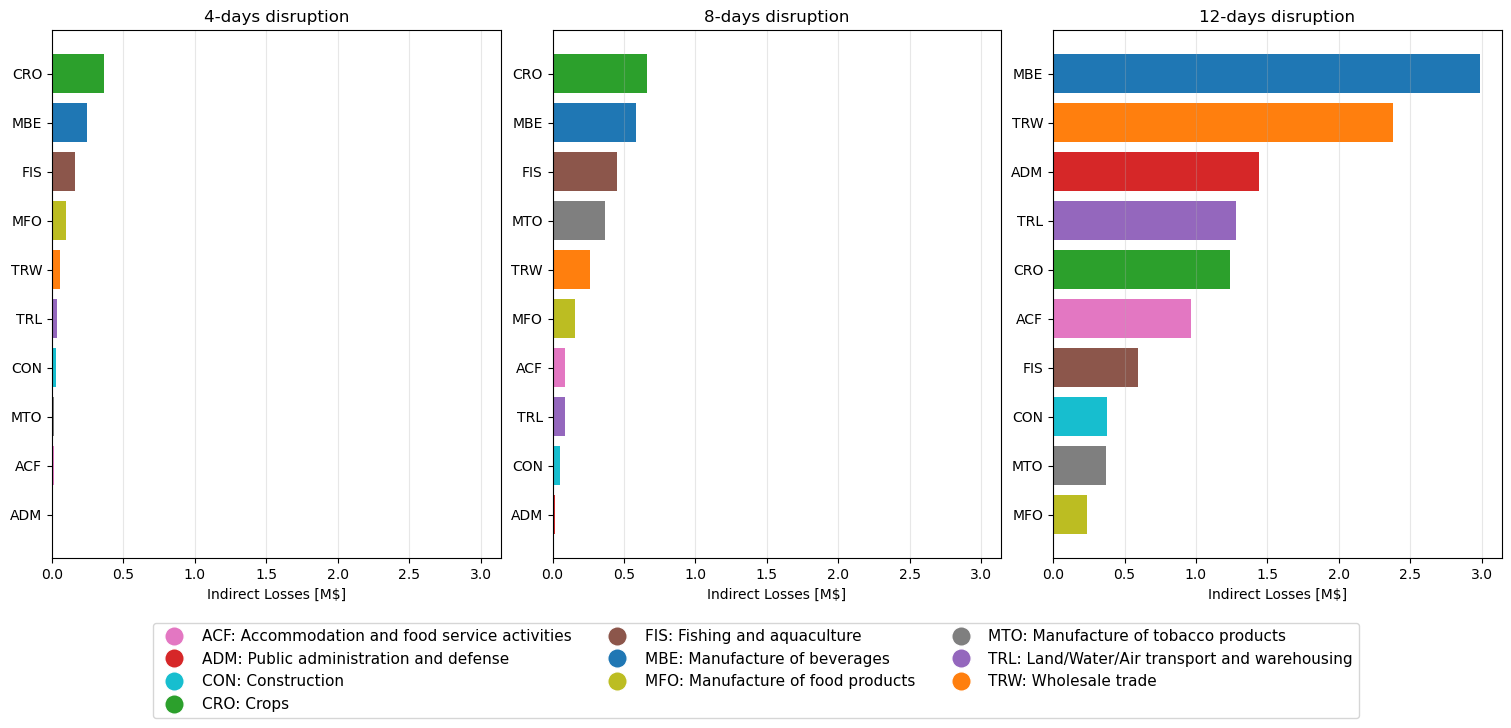

In [6]:
# Cumulative sectoral losses by disruption duration
fig, axes = plt.subplots(1, 3, figsize=(15, 6), constrained_layout=True)

for idx, duration in enumerate(durations):
    df = data_dict[duration]
    sector_losses = df.groupby('sector')['loss'].sum()
    top_losses = sector_losses[top_10_sectors].sort_values(ascending=True)

    ax = axes[idx]
    ax.barh(range(len(top_losses)), top_losses.values,
            color=[sector_colors[s] for s in top_losses.index])
    ax.set_yticks(range(len(top_losses)))
    ax.set_yticklabels([s.replace('KHM_', '') for s in top_losses.index])
    ax.set_xlabel('Indirect Losses [M$]')
    ax.set_title(f'{duration[:-1]}-days disruption')
    ax.grid(axis='x', alpha=0.3)

xlim_max = max(ax.get_xlim()[1] for ax in axes)
for ax in axes:
    ax.set_xlim(0, xlim_max)

legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                              markerfacecolor=sector_colors[sector], markersize=14,
                              label=f"{sector.replace('KHM_', '')}: {sector_name_dict.get(sector, sector)}")
                  for sector in top_10_sectors]
legend_elements = sorted(legend_elements, key=lambda x: x.get_label())

fig.legend(handles=legend_elements, loc='lower center', fontsize=11,
          bbox_to_anchor=(0.5, -0.2), frameon=True, ncol=3)

plt.savefig(FIGDIR / 'fig_sectors_losses_short.png', dpi=100, bbox_inches='tight')
plt.show()

### Cumulative losses and representative simulation

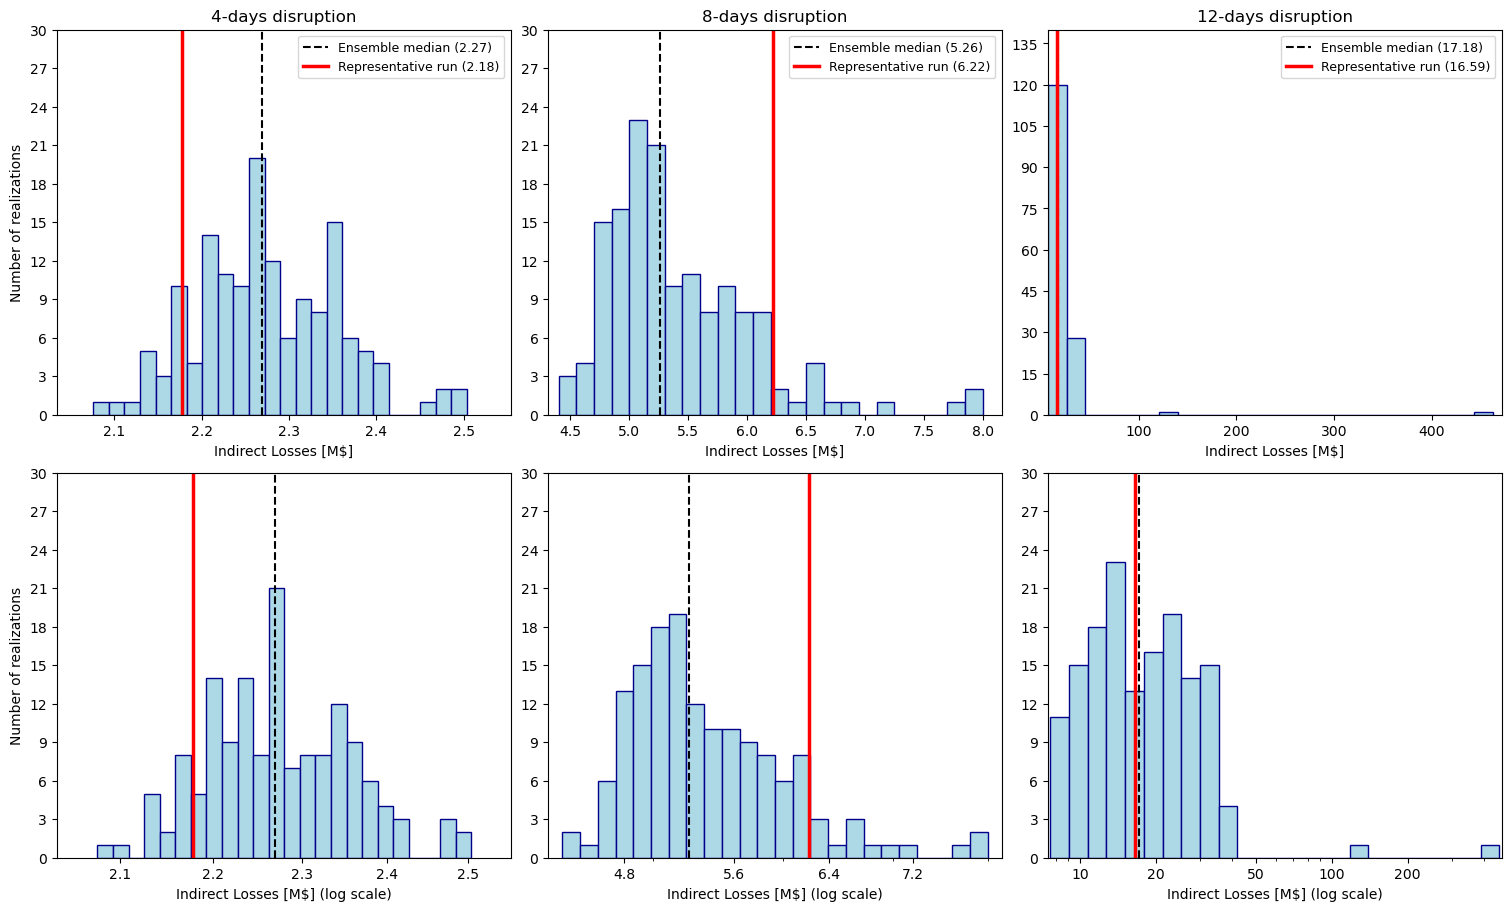

In [7]:
from matplotlib.ticker import LogLocator, MaxNLocator, NullFormatter, ScalarFormatter
df_ens = pd.concat([
    pd.read_csv(MC / 'cambodia_simulations_results_230927_singlevsmulti.csv'),
    pd.read_csv(MC / 'cambodia_simulations_results_230927_cascading.csv'),
], ignore_index=True)
df_ens = df_ens[(df_ens['simulation_name'] == 'cascading_hazards_0d') &
                (df_ens['filename'] != 'disruption_0614936972_3829663.csv')]

# y-axis caps: top row (absolute) lets 12d go higher; bottom row (log) uniform at 30
YLIM_ABS = {'4d': 30, '8d': 30, '12d': 140}
YLIM_LOG = 30

# top row: absolute values; bottom row: log scale
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for col, dur in enumerate(durations):
    x = df_ens.loc[df_ens['duration'] == int(dur[:-1]), 'household_loss']
    rep = pd.read_csv(SCEN / f'230927_simultaneous_{dur}/loss_summary.csv')['households'].iloc[0]
    pct = 100 * (x < rep).mean()

    lo, hi = 0.999 * x.min(), 1.001 * x.max()   # small margin so the extreme runs fall inside the outer bins
    for row, log_x in enumerate([False, True]):
        ax = axes[row, col]
        bins = np.logspace(np.log10(lo), np.log10(hi), 25) if log_x else np.linspace(lo, hi, 25)
        ax.hist(x, bins=bins, color='lightblue', edgecolor='darkblue')
        ax.axvline(x.median(), color='black', linestyle='--', linewidth=1.5, label=f'Ensemble median ({x.median():.2f})')
        ax.axvline(rep, color='red', linewidth=2.5, label=f'Representative run ({rep:.2f})')
        if log_x:
            ax.set_xscale('log')
            ticks = (LogLocator(subs=(1, 2, 5)).tick_values(lo, hi) if hi / lo > 10
                     else MaxNLocator(5).tick_values(lo, hi))
            ax.set_xticks([t for t in ticks if lo <= t <= hi])
            ax.xaxis.set_major_formatter(ScalarFormatter())
            ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlim(bins[0] * 0.98, bins[-1] * 1.02)
        ax.set_ylim(0, YLIM_LOG if log_x else YLIM_ABS[dur])
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlabel('Indirect Losses [M$]' + (' (log scale)' if log_x else ''))
        if row == 0:
            ax.set_title(f'{dur[:-1]}-days disruption')
            ax.legend(fontsize=9)
for row in range(2):
    axes[row, 0].set_ylabel('Number of realizations')

plt.savefig(FIGDIR / 'fig_representativeness_test.png', dpi=100, bbox_inches='tight')
plt.show()

In [8]:
def rep_verdict(x, rep):
    med = x.median()
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    pct = 100 * (x < rep).mean()
    d_iqr = abs(rep - med) / iqr if iqr > 0 else np.inf

    if   25 <= pct <= 75 and d_iqr <= 0.5: v = 'OK'
    elif 10 <= pct <= 90 and d_iqr <= 1.0: v = 'borderline'
    else:                                    v = 'TAIL / off'
    return pct, d_iqr, v

print(f"{'dur':<4} {'rep':>8} {'median':>8} {'IQR':>7} {'pctile':>7} {'d_iqr':>7}  verdict")
for dur in durations:
    x   = df_ens.loc[df_ens['duration'] == int(dur[:-1]), 'household_loss']
    rep = pd.read_csv(SCEN / f'230927_simultaneous_{dur}/loss_summary.csv')['households'].iloc[0]
    pct, d_iqr, v = rep_verdict(x, rep)
    iqr = x.quantile(0.75) - x.quantile(0.25)
    print(f'{dur:<4} {rep:8.3f} {x.median():8.3f} {iqr:7.3f} {pct:6.1f}% {d_iqr:7.2f}  {v}')

dur       rep   median     IQR  pctile   d_iqr  verdict
4d      2.178    2.269   0.125   12.0%    0.73  borderline
8d      6.224    5.261   0.773   91.3%    1.25  TAIL / off
12d    16.587   17.182  12.698   48.0%    0.05  OK


#### Check representativness with new runs

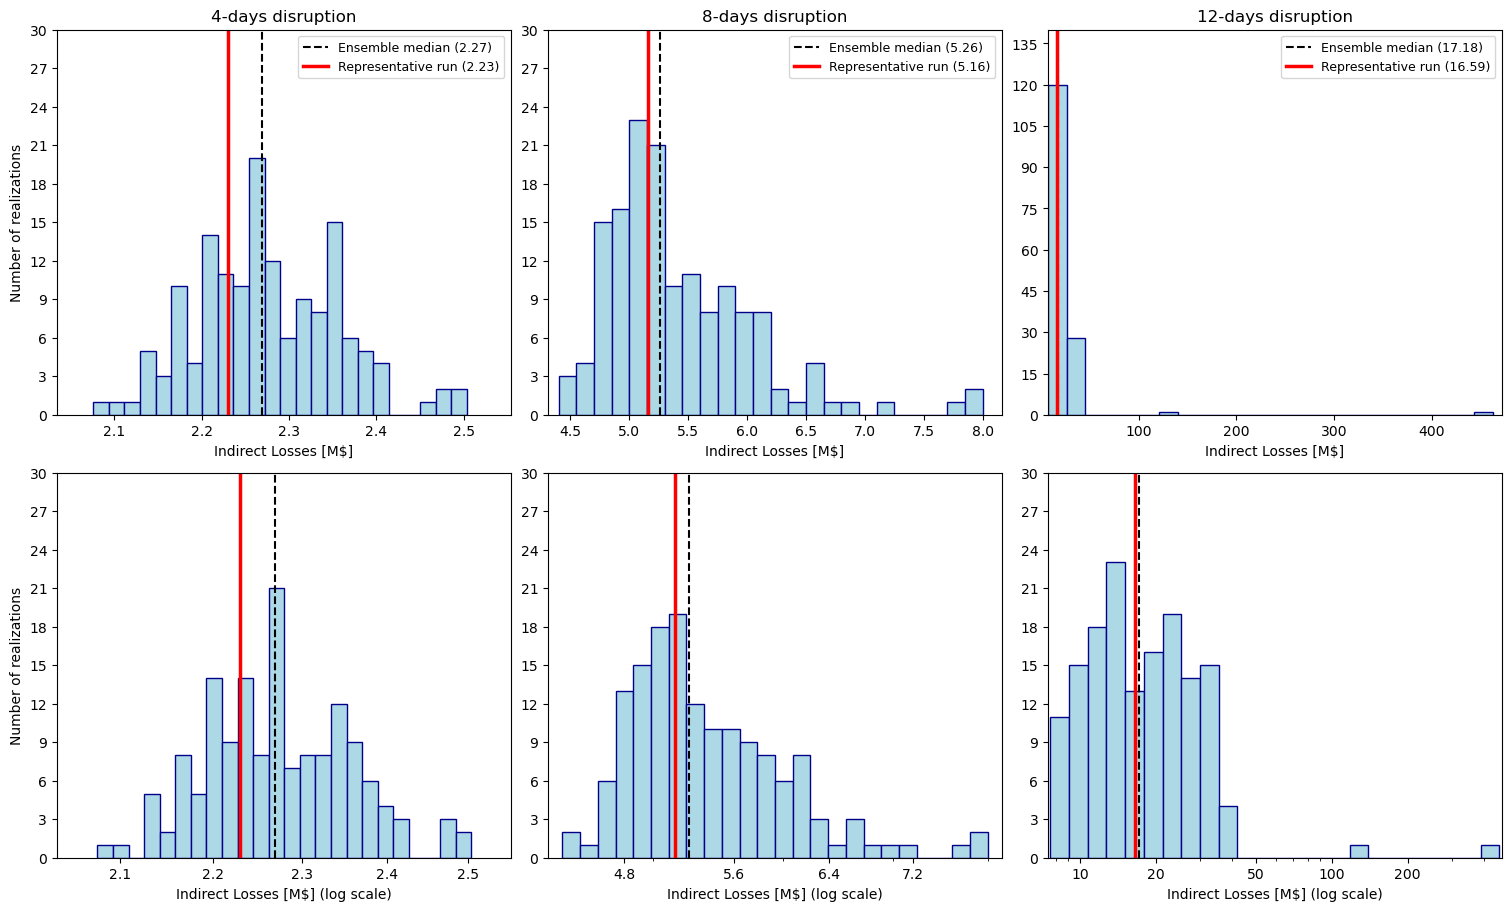

In [9]:
from matplotlib.ticker import LogLocator, MaxNLocator, NullFormatter, ScalarFormatter
df_ens = pd.concat([
    pd.read_csv(MC / 'cambodia_simulations_results_230927_singlevsmulti.csv'),
    pd.read_csv(MC / 'cambodia_simulations_results_230927_cascading.csv'),
], ignore_index=True)
df_ens = df_ens[(df_ens['simulation_name'] == 'cascading_hazards_0d') &
                (df_ens['filename'] != 'disruption_0614936972_3829663.csv')]

# y-axis caps: top row (absolute) lets 12d go higher; bottom row (log) uniform at 30
YLIM_ABS = {'4d': 30, '8d': 30, '12d': 140}
YLIM_LOG = 30

# top row: absolute values; bottom row: log scale
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for col, dur in enumerate(durations):
    x = df_ens.loc[df_ens['duration'] == int(dur[:-1]), 'household_loss']
    rep_dir = f'230927_simultaneous_{dur}_v2' if dur in ('4d', '8d') else f'230927_simultaneous_{dur}'
    rep = pd.read_csv(SCEN / f'{rep_dir}/loss_summary.csv')['households'].iloc[0]
    pct = 100 * (x < rep).mean()

    lo, hi = 0.999 * x.min(), 1.001 * x.max()   # small margin so the extreme runs fall inside the outer bins
    for row, log_x in enumerate([False, True]):
        ax = axes[row, col]
        bins = np.logspace(np.log10(lo), np.log10(hi), 25) if log_x else np.linspace(lo, hi, 25)
        ax.hist(x, bins=bins, color='lightblue', edgecolor='darkblue')
        ax.axvline(x.median(), color='black', linestyle='--', linewidth=1.5, label=f'Ensemble median ({x.median():.2f})')
        ax.axvline(rep, color='red', linewidth=2.5, label=f'Representative run ({rep:.2f})')
        if log_x:
            ax.set_xscale('log')
            ticks = (LogLocator(subs=(1, 2, 5)).tick_values(lo, hi) if hi / lo > 10
                     else MaxNLocator(5).tick_values(lo, hi))
            ax.set_xticks([t for t in ticks if lo <= t <= hi])
            ax.xaxis.set_major_formatter(ScalarFormatter())
            ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlim(bins[0] * 0.98, bins[-1] * 1.02)
        ax.set_ylim(0, YLIM_LOG if log_x else YLIM_ABS[dur])
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlabel('Indirect Losses [M$]' + (' (log scale)' if log_x else ''))
        if row == 0:
            ax.set_title(f'{dur[:-1]}-days disruption')
            ax.legend(fontsize=9)
for row in range(2):
    axes[row, 0].set_ylabel('Number of realizations')

plt.savefig(FIGDIR / 'fig_representativeness_test_v2.png', dpi=100, bbox_inches='tight')
plt.show()

In [10]:
def rep_verdict(x, rep):
    med = x.median()
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    pct = 100 * (x < rep).mean()
    d_iqr = abs(rep - med) / iqr if iqr > 0 else np.inf

    if   25 <= pct <= 75 and d_iqr <= 0.5: v = 'OK'
    elif 10 <= pct <= 90 and d_iqr <= 1.0: v = 'borderline'
    else:                                    v = 'TAIL / off'
    return pct, d_iqr, v

print(f"{'dur':<4} {'rep':>8} {'median':>8} {'IQR':>7} {'pctile':>7} {'d_iqr':>7}  verdict")
for dur in ('4d', '8d'):
    x   = df_ens.loc[df_ens['duration'] == int(dur[:-1]), 'household_loss']
    rep = pd.read_csv(SCEN / f'230927_simultaneous_{dur}_v2/loss_summary.csv')['households'].iloc[0]
    pct, d_iqr, v = rep_verdict(x, rep)
    iqr = x.quantile(0.75) - x.quantile(0.25)
    print(f'{dur:<4} {rep:8.3f} {x.median():8.3f} {iqr:7.3f} {pct:6.1f}% {d_iqr:7.2f}  {v}')

dur       rep   median     IQR  pctile   d_iqr  verdict
4d      2.230    2.269   0.125   30.7%    0.31  OK
8d      5.158    5.261   0.773   41.3%    0.13  OK


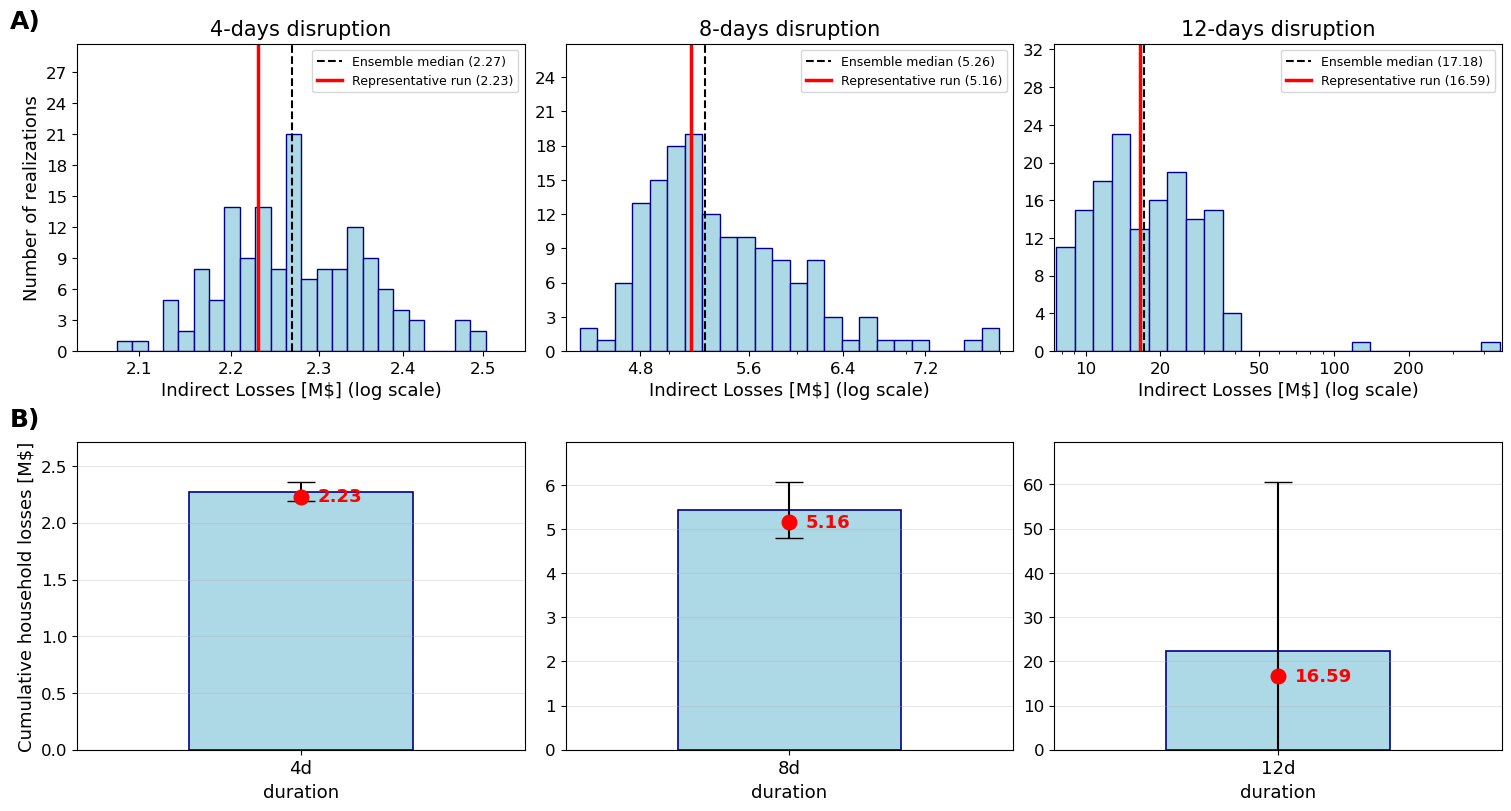

In [11]:
# Simple two-row summary of representativeness
#   Panel A : log-scale histogram of the MC ensemble with median + rep (red line)
#   Panel B : ensemble mean +- 1 std as bar with whiskers; red dot = representative run (value inline)
from matplotlib.ticker import LogLocator, MaxNLocator, NullFormatter, ScalarFormatter

df_ens = pd.concat([
    pd.read_csv(MC / 'cambodia_simulations_results_230927_singlevsmulti.csv'),
    pd.read_csv(MC / 'cambodia_simulations_results_230927_cascading.csv'),
], ignore_index=True)
df_ens = df_ens[(df_ens['simulation_name'] == 'cascading_hazards_0d') &
                (df_ens['filename'] != 'disruption_0614936972_3829663.csv')]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for col, dur in enumerate(durations):
    x = df_ens.loc[df_ens['duration'] == int(dur[:-1]), 'household_loss']
    rep = pd.read_csv(SCEN / f'{scen_dir(dur)}/loss_summary.csv')['households'].iloc[0]

    # --- Panel A: log-scale histogram
    ax = axes[0, col]
    lo, hi = 0.999 * x.min(), 1.001 * x.max()
    bins = np.logspace(np.log10(lo), np.log10(hi), 25)
    ax.hist(x, bins=bins, color='lightblue', edgecolor='darkblue')
    ax.axvline(x.median(), color='black', linestyle='--', linewidth=1.5,
               label=f'Ensemble median ({x.median():.2f})')
    ax.axvline(rep, color='red', linewidth=2.5,
               label=f'Representative run ({rep:.2f})')
    ax.set_xscale('log')
    ticks = (LogLocator(subs=(1, 2, 5)).tick_values(lo, hi) if hi / lo > 10
             else MaxNLocator(5).tick_values(lo, hi))
    ax.set_xticks([t for t in ticks if lo <= t <= hi])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(bins[0] * 0.98, bins[-1] * 1.02)
    # headroom above the tallest bar so the legend has empty space to sit in
    ymax = ax.get_ylim()[1]
    ax.set_ylim(0, ymax * 1.35)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel('Indirect Losses [M$] (log scale)', fontsize=13)
    ax.set_title(f'{dur[:-1]}-days disruption', fontsize=15)
    ax.tick_params(labelsize=12)
    # inside the plot, two rows (one entry per row)
    ax.legend(fontsize=9, ncol=1, loc='upper right', frameon=True)
    if col == 0:
        ax.set_ylabel('Number of realizations', fontsize=13)
        ax.text(-0.15, 1.05, 'A)', transform=ax.transAxes, fontsize=18, fontweight='bold')

    # --- Panel B: ensemble mean +- 1 std, red dot = rep (value inline, no legend)
    ax = axes[1, col]
    mean, std = x.mean(), x.std()
    ax.bar([0], [mean], yerr=[std], capsize=10,
           color='lightblue', edgecolor='darkblue', linewidth=1.2,
           error_kw=dict(ecolor='black', elinewidth=1.5))
    ax.scatter([0], [rep], color='red', s=110, zorder=5)
    ax.annotate(f'{rep:.2f}', xy=(0, rep), xytext=(12, 0),
                textcoords='offset points', color='red', fontsize=13,
                va='center', fontweight='bold')

    ax.set_xticks([0])
    ax.set_xticklabels([f'{dur[:-1]}d'], fontsize=13)
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(0, max(mean + std, rep) * 1.15)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_xlabel('duration', fontsize=13)
    if col == 0:
        ax.set_ylabel('Cumulative household losses [M$]', fontsize=13)
        ax.text(-0.15, 1.05, 'B)', transform=ax.transAxes, fontsize=18, fontweight='bold')

plt.savefig(FIGDIR / 'fig_representativeness_summary.png', dpi=100, bbox_inches='tight')
plt.show()

Looking at the test above, I noticed that the original representative realizations had been picked based on cumulative losses restricted to Cambodian sectors (`KHM_` only). That criterion is consistent with the spatial map in panel B, which shows only the domestic component of household losses. However, when the same realizations are compared against the Monte Carlo ensemble on *total* household losses (domestic + imported goods), they drift away from the median — most clearly at 8 days, where the original run sits at the 91st percentile and is flagged as `TAIL/off`.

The v2 realizations were selected so that their total household losses fall close to the ensemble median. Including this check in the supplementary material would help justify showing a single representative realization in the main figures, without needing to display the full MC distribution.